# Wind Forecast Desk: January 2026 analysis

National GB wind, Elexon BMRS only. Actuals are `FUELHH` (fuelType `WIND`, half-hourly) and forecasts are `WINDFOR` (hourly, about 8 runs a day).
Decisions are made on D-1 for 1–31 January 2026, so delivery days are **2 January – 1 February 2026**.

This notebook imports the same code the API runs (`backend/app`), so every number here matches the app.
Error is **forecast − actual**: positive means the forecast was too high.

In [1]:
import sys
from datetime import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "backend").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "backend"))

from app import analytics as an  # noqa: E402
from app import config  # noqa: E402
from app.ingest import load_snapshot  # noqa: E402
from app.service import Query, WindService  # noqa: E402

pd.set_option("display.float_format", "{:,.1f}".format)
snap = load_snapshot()
svc = WindService(snap)
print(f"Snapshot {snap.version}, fetched {snap.fetched_at}")

Snapshot v1, fetched 2026-10-25T07:10:33+00:00


## 1. Data quality

In [2]:
a, f = snap.actuals, snap.forecasts
per_day = an.delivery_date(a["start_time"]).value_counts()
dq = pd.DataFrame(
    {
        "FUELHH (actuals)": {
            "rows": len(a),
            "first": a["start_time"].min(),
            "last": a["start_time"].max(),
            "delivery days": per_day.size,
            "days without 48 half-hours": int((per_day != 48).sum()),
            "missing half-hours": snap.quality["actuals"]["missing_half_hours"],
            "duplicates dropped": snap.quality["actuals"]["duplicates_dropped"],
            "null generation": int(a["generation"].isna().sum()),
            "negative generation": int((a["generation"] < 0).sum()),
        },
        "WINDFOR (forecasts)": {
            "rows": len(f),
            "first": f["start_time"].min(),
            "last": f["start_time"].max(),
            "publish runs": f["publish_time"].nunique(),
            "rows outside 0-48h dropped": snap.quality["forecasts"]["rows_outside_horizon_dropped"],
            "duplicates dropped": snap.quality["forecasts"]["duplicates_dropped"],
            "null generation": int(f["generation"].isna().sum()),
            "negative generation": int((f["generation"] < 0).sum()),
            "horizon range (h)": f"{f['horizon_h'].min():.1f} - {f['horizon_h'].max():.1f}",
        },
    }
)
dq.fillna("")

,FUELHH (actuals),WINDFOR (forecasts)
rows,1488,12639
first,2026-01-02 00:00:00+00:00,2025-12-31 03:00:00+00:00
last,2026-02-01 23:30:00+00:00,2026-02-03 21:00:00+00:00
delivery days,31,
days without 48 half-hours,0,
missing half-hours,0,
duplicates dropped,0,0
null generation,0,0
negative generation,0,0
publish runs,,264


**Alignment.** WINDFOR is hourly and FUELHH is half-hourly average MW. Each hour's actual is the mean of its two half-hours (an hour missing either half is dropped).
**Time zones.** Everything is UTC internally. A delivery day is a Europe/London calendar day, and UK time equals UTC in January.

In [3]:
hourly = svc.actual
print(f"hourly actuals: {len(hourly)} (= 31 days x 24 = {31 * 24})")
assert len(hourly) == 31 * 24
assert per_day.index.min() == config.DELIVERY_START and per_day.index.max() == config.DELIVERY_END

hourly actuals: 744 (= 31 days x 24 = 744)


## 2. Which forecast was available at decision time?

For one delivery hour, here is every WINDFOR run that forecast it, and the one each selection rule picks. The D-1 09:00 cutoff picks the 07:30 run, and the 09:30 run arrives just after it.

In [4]:
target = pd.Timestamp("2026-01-11T10:00Z")
runs = f[f["start_time"] == target].sort_values("publish_time")[["publish_time", "horizon_h", "generation"]]
cut = an.cutoff_utc(target.date(), config.DEFAULT_CUTOFF)
runs["usable at D-1 09:00"] = runs["publish_time"] <= cut
print(f"target {target}, cutoff {cut}")
runs.tail(10)

target 2026-01-11 10:00:00+00:00, cutoff 2026-01-10 09:00:00+00:00


,publish_time,horizon_h,generation,usable at D-1 09:00
4095,2026-01-10 07:30:00+00:00,26.5,"18,995.0",True
4045,2026-01-10 09:30:00+00:00,24.5,"18,883.0",False
3995,2026-01-10 11:30:00+00:00,22.5,"18,835.0",False
3943,2026-01-10 15:30:00+00:00,18.5,"18,775.0",False
3892,2026-01-10 18:30:00+00:00,15.5,"19,066.0",False
3841,2026-01-10 22:30:00+00:00,11.5,"18,965.0",False
3789,2026-01-11 02:30:00+00:00,7.5,"19,041.0",False
3739,2026-01-11 04:30:00+00:00,5.5,"18,946.0",False
3688,2026-01-11 07:30:00+00:00,2.5,"18,766.0",False
3638,2026-01-11 09:30:00+00:00,0.5,"18,932.0",False


In [5]:
picked = an.select_decision(f[f["start_time"] == target])
assert picked["publish_time"].iloc[0] == runs.loc[runs["usable at D-1 09:00"], "publish_time"].max()
picked

,start_time,publish_time,generation,horizon_h
0,2026-01-11 10:00:00+00:00,2026-01-10 07:30:00+00:00,"18,995.0",26.5


## 3. Accuracy of the forecast available at decision time (D-1 09:00)

In [6]:
def summary(q: Query) -> dict:
    m, _ = svc.metrics(q)
    return {
        k: m[k]
        for k in [
            "n",
            "mae",
            "rmse",
            "bias",
            "mae_pct_of_mean_actual",
            "p50_abs_error",
            "p90_abs_error",
            "p99_abs_error",
            "pct_over",
            "pct_under",
            "forecast_mean",
            "firm_wind_p10_mean",
        ]
    }


rows = {"decision D-1 09:00": summary(Query())}
for h in (0, 4, 24, 40):
    rows[f"horizon >= {h}h"] = summary(Query(mode="horizon", horizon_h=h))
headline = pd.DataFrame(rows).T
headline

,n,mae,rmse,bias,mae_pct_of_mean_actual,p50_abs_error,p90_abs_error,p99_abs_error,pct_over,pct_under,forecast_mean,firm_wind_p10_mean
decision D-1 09:00,744.0,"2,038.9","2,504.8","1,747.9",18.1,"1,671.0","4,097.9","6,261.3",84.9,15.1,"13,031.4","9,045.0"
horizon >= 0h,744.0,"1,686.8","2,149.7","1,473.1",14.9,"1,350.0","3,438.1","6,279.8",85.5,14.5,"12,756.7","9,312.8"
horizon >= 4h,744.0,"1,730.3","2,209.0","1,526.4",15.3,"1,391.0","3,617.8","6,441.2",87.4,12.6,"12,809.9","9,331.4"
horizon >= 24h,744.0,"1,947.7","2,407.3","1,738.1",17.3,"1,625.8","3,862.5","6,261.3",87.1,12.9,"13,021.7","9,136.5"
horizon >= 40h,744.0,"2,206.4","2,730.6","1,849.2",19.6,"1,921.2","4,326.8","7,036.1",84.1,15.9,"13,132.7","8,778.6"


## 4. Error grows with lead time

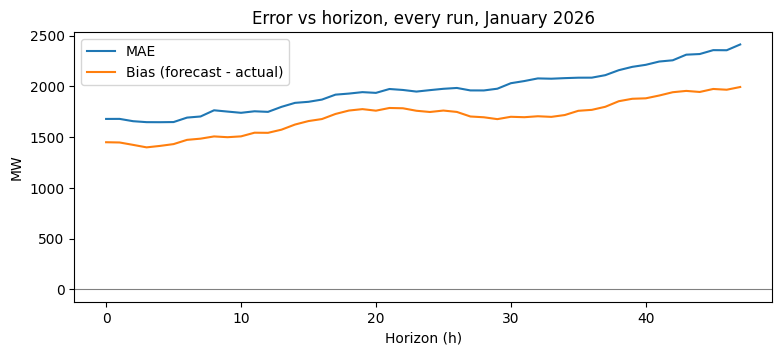

,horizon_h,n,mae,rmse,bias,p90_abs_error
0,0,248,"1,679.5","2,134.1","1,450.0","3,463.1"
6,6,248,"1,692.6","2,145.8","1,473.4","3,560.9"
12,12,248,"1,749.0","2,227.5","1,542.6","3,732.1"
24,24,248,"1,963.0","2,420.9","1,747.8","3,889.9"
36,36,248,"2,086.0","2,591.2","1,768.9","4,096.0"
47,47,217,"2,412.7","2,967.2","1,993.8","4,790.9"


In [7]:
hz = svc.by_horizon(Query())
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(hz["horizon_h"], hz["mae"], label="MAE")
ax.plot(hz["horizon_h"], hz["bias"], label="Bias (forecast - actual)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Horizon (h)")
ax.set_ylabel("MW")
ax.legend()
ax.set_title("Error vs horizon, every run, January 2026")
plt.show()
hz.iloc[[0, 6, 12, 24, 36, -1]]

## 5. Is the 09:00 cutoff the right one?

The cutoff is configurable. Moving it later lets the desk use a fresher run, but only if bids can still be submitted before gate closure.

In [8]:
sens = pd.DataFrame(
    {c: summary(Query(cutoff=time.fromisoformat(c))) for c in ["06:00", "08:00", "09:00", "10:00", "12:00"]}
).T[["n", "mae", "bias", "p90_abs_error"]]
sens

,n,mae,bias,p90_abs_error
06:00,744.0,"2,016.1","1,671.0","4,157.9"
08:00,744.0,"2,038.9","1,747.9","4,097.9"
09:00,744.0,"2,038.9","1,747.9","4,097.9"
10:00,744.0,"2,013.0","1,729.9","4,143.9"
12:00,744.0,"1,901.0","1,687.2","3,847.2"


## 6. Over/under-forecast and hour of day

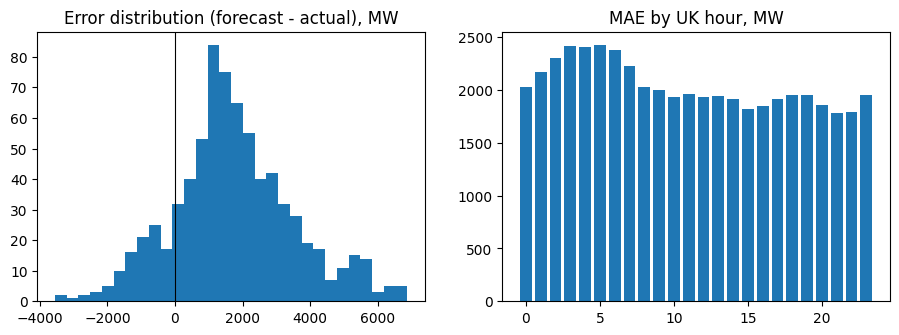

,hour,n,mae,rmse,bias,p90_abs_error
5,5,31,"2,429.9","2,919.2","2,358.1","4,844.0"
3,3,31,"2,413.1","2,908.7","2,321.7","4,512.0"
4,4,31,"2,405.2","2,904.4","2,334.6","4,756.0"


In [9]:
sel = svc.selected(Query())
by_hour = an.error_by_hour(sel)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(sel["error"], bins=30)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("Error distribution (forecast - actual), MW")
axes[1].bar(by_hour["hour"], by_hour["mae"])
axes[1].set_title("MAE by UK hour, MW")
plt.show()
by_hour.sort_values("mae", ascending=False).head(3)

## 7. Reliability bands: in-sample vs out-of-sample

The app's P10/P90 bands use error quantiles per 6-hour horizon bucket, fitted on the whole month (in-sample, documented in the README).
To check how much that flatters them, fit on the first half of the month and test coverage on the second half.

In [10]:
pairs = svc.pairs
d = an.delivery_date(pairs["start_time"])
split = pd.Timestamp("2026-01-17").date()
q_train = an.error_quantiles_by_horizon(pairs[d < split])
q_all = svc.qtable

test = an.in_delivery_range(sel, split, config.DELIVERY_END)


def coverage(qtable: pd.DataFrame) -> dict:
    b = an.apply_bands(test, qtable)
    return {
        "P10 <= actual <= P90 (%)": ((b["actual"] >= b["p10"]) & (b["actual"] <= b["p90"])).mean() * 100,
        "actual >= P10 (%)": (b["actual"] >= b["p10"]).mean() * 100,
    }


cov = pd.DataFrame({"in-sample (whole month)": coverage(q_all), "out-of-sample (fit 2-16 Jan)": coverage(q_train)}).T
cov

,P10 <= actual <= P90 (%),actual >= P10 (%)
in-sample (whole month),82.3,90.4
out-of-sample (fit 2-16 Jan),88.8,91.4


## 8. Conclusions (computed)

In [11]:
m = headline.loc["decision D-1 09:00"]
cutoff_gain = sens.loc["10:00", "mae"] - sens.loc["09:00", "mae"]
lines = [
    f"Over-forecast in {m.pct_over:.0f}% of hours, mean bias {m.bias:+,.0f} MW.",
    f"MAE {m.mae:,.0f} MW ({m.mae_pct_of_mean_actual:.0f}% of mean actual); P90 abs error {m.p90_abs_error:,.0f} MW.",
    f"MAE rises from {hz['mae'].iloc[0]:,.0f} MW at 0h to {hz['mae'].iloc[-1]:,.0f} MW at {hz['horizon_h'].iloc[-1]}h.",
    f"Firm wind (P10) averages {m.firm_wind_p10_mean:,.0f} MW vs a mean forecast of {m.forecast_mean:,.0f} MW.",
    f"Moving the cutoff from 09:00 to 10:00 changes MAE by {cutoff_gain:+,.0f} MW.",
    f"Out-of-sample P10 coverage: {cov.iloc[1, 1]:.0f}% of hours at or above P10 (target 90%).",
]
print("\n".join(lines))

Over-forecast in 85% of hours, mean bias +1,748 MW.
MAE 2,039 MW (18% of mean actual); P90 abs error 4,098 MW.
MAE rises from 1,680 MW at 0h to 2,413 MW at 47h.
Firm wind (P10) averages 9,045 MW vs a mean forecast of 13,031 MW.
Moving the cutoff from 09:00 to 10:00 changes MAE by -26 MW.
Out-of-sample P10 coverage: 91% of hours at or above P10 (target 90%).
